# Task 2 – Approach 1: Context / Query Reduction
**Reducing long prompts while keeping the information needed for difficulty classification** · Prepared by Prabhu Teja



In [1]:
# ---- change these ----
REDUCER = "llmlingua"
RATES   = [0.7, 0.5, 0.3]  # fraction of tokens KEPT (0.5 = keep half)
N_SPLITS = 5               # number of random 70/30 train/test splits that are averaged
# ----------------------
# For the real run, uncomment:  !pip install llmlingua==0.2.2 scikit-learn pandas matplotlib
import re, os, json, time, math, random, hashlib, collections, textwrap
from collections import Counter
from dataclasses import dataclass
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
print("Reducer:", REDUCER, "| rates:", RATES, "| splits:", N_SPLITS)

Reducer: llmlingua | rates: [0.7, 0.5, 0.3] | splits: 5


## 1. Dataset (subtask 2.8)
144 synthetic coding-style prompts: **48 Easy, 48 Medium, 48 Hard**. Inside every label, half are *short* (a small code snippet) and half are *long* (~600 words of logs, repeated documentation, unrelated chat, stack traces).
The **label depends only on the request (the "ask")**, never on the noise – so long+simple and short+complex prompts both exist (idea of Task 1.6: length ≠ difficulty).
Each row keeps `context` and `ask` separately so we can later test "compress context only, keep the ask".

⚠ Synthetic data = good for checking the pipeline, **not** for final claims.

In [2]:
rng = random.Random(42)
SUBJECTS = [  # phrase, module, function, variable
    ("the login handler", "auth.py", "login_user", "usr_name"),
    ("the payment service", "payments.py", "charge_card", "amount_cents"),
    ("the CSV exporter", "export.py", "write_csv", "file_path"),
    ("the cache layer", "cache.py", "get_cached", "ttl_seconds"),
    ("the job scheduler", "scheduler.py", "run_job", "job_queue"),
    ("the search indexer", "indexer.py", "build_index", "doc_ids"),
    ("the notification worker", "notify.py", "send_email", "recipient"),
    ("the image resizer", "resize.py", "resize_image", "target_width"),
    ("the rate limiter", "limiter.py", "allow_request", "bucket_size"),
    ("the session store", "sessions.py", "load_session", "session_id"),
    ("the report generator", "reports.py", "make_report", "date_range"),
    ("the websocket gateway", "gateway.py", "on_message", "client_id"),
]
EASY = [
    "Fix the typo in the variable name `{var}` inside {subj}.",
    "Rename the function `{fn}` to `{fn}_v2` in {subj}.",
    "Add a one-line docstring to `{fn}` in {subj}.",
    "Change the default port used by {subj} from 8000 to 8080.",
    "Remove the unused import from {mod}.",
    "What does the `{fn}` function in {subj} return?",
    "Update the log message in {subj} to say 'started' instead of 'start'.",
    "Add a unit test for the existing `{fn}` helper that checks its default value.",
]
MEDIUM = [
    "Add input validation for empty and negative values to {subj} and write unit tests for the new checks.",
    "Refactor {subj} to use async/await and keep the public API unchanged.",
    "Write a SQL query that joins the orders and customers tables for {subj} and returns the top 10 customers by monthly revenue.",
    "Add retry with exponential backoff to the HTTP calls in {subj} and make the retry limit configurable.",
    "Implement cursor-based pagination for {subj} and update the existing tests.",
    "Explain why {subj} returns a stale value after the cache TTL expires and propose a fix.",
    "Migrate the configuration of {subj} from YAML to environment variables while keeping backward compatibility.",
    "Write unit tests for `{fn}` that cover edge cases and mock the database connection.",
]
HARD = [
    "Diagnose the intermittent race condition in {subj} that only appears under high concurrency across several worker processes, and propose a lock-free redesign with a correctness argument.",
    "Design a distributed consensus protocol for {subj} that tolerates network partitions and Byzantine nodes, and prove its safety and liveness.",
    "Find the root cause of the memory leak that causes out-of-memory crashes in {subj} after several days under load, considering the garbage collector, native extensions and connection pools.",
    "Optimize {subj} from O(n^2) to O(n log n) for ten million records while keeping exact results and bounded memory, and justify the complexity.",
    "Implement exactly-once delivery semantics for {subj} across multiple microservices, with idempotency, ordering guarantees and failure recovery.",
    "Redesign the sharding strategy of {subj} so live traffic can be rebalanced without downtime, handling hot keys and cross-shard transactions.",
    "Reproduce and fix the deadlock between the scheduler and the I/O thread pool in {subj} that happens only on NUMA machines.",
    "Write property-based tests that expose the race condition in {subj} and formally verify that its state machine never reaches an inconsistent state.",
]
TEMPLATES = {"Easy": EASY, "Medium": MEDIUM, "Hard": HARD}
SUFFIX = {"Easy": ["", "", " Nothing else needs to change."],
          "Medium": ["", " Keep the change small.", ""],
          "Hard": ["", " Explain your reasoning step by step.", ""]}

# ---- noise blocks (same distribution for every label) ----
MODULES = ["db.pool", "http.client", "cache.redis", "worker.main", "api.router", "metrics"]
MESSAGES = ["Connection pool size={a} active={b} idle={c}", "Request {r} completed in {a} ms status=200",
            "Cache miss for key user:{a}", "Retrying upstream call attempt={b}", "GC pause {a} ms heap={c}MB",
            "Heartbeat received from node-{b}", "Flushing {a} buffered metrics to collector"]
DOC_PARAS = [
    "The service reads its settings from the configuration file at start-up. Every option has a default value, and values in the environment override values in the file. See the deployment guide for the full list of options.",
    "All public functions are documented with their arguments and return values. Errors are reported with exceptions that derive from the base error class of the package. Logging uses the standard logging module.",
    "To run the test suite, install the development dependencies and execute the test runner from the project root. Tests are grouped by module and may be run individually."]
CHAT = [("Thanks, that worked for the staging deploy.", "Glad to hear it. Let me know if the build fails again."),
        ("Can you remind me how to restart the container?", "Use the restart command from the ops runbook, then check the health endpoint."),
        ("The meeting moved to Thursday afternoon.", "Noted. I will update the release checklist."),
        ("Did the nightly job finish?", "Yes, it finished at 03:12 without warnings.")]
CODE_LINES = ["    result = []", "    for item in items:", "        if item is None:", "            continue",
              "        result.append(item)", "    return result", "    logger.debug('done')", "    value = config.get('mode', 'fast')"]

def log_block(n):
    out = []
    for _ in range(n):
        m = rng.choice(MESSAGES).format(a=rng.randint(1, 900), b=rng.randint(1, 9), c=rng.randint(10, 512),
                                         r=''.join(rng.choice('abcdef0123456789') for _ in range(8)))
        out.append(f"2026-03-{rng.randint(1,28):02d} {rng.randint(0,23):02d}:{rng.randint(0,59):02d}:{rng.randint(0,59):02d},"
                   f"{rng.randint(0,999):03d} {rng.choice(['INFO','INFO','DEBUG','WARN'])} [{rng.choice(['T-1','T-2','T-3'])}] "
                   f"{rng.choice(MODULES)}: {m}")
    return "\n".join(out)

def trace_block(mod, fn):
    lines = ["Traceback (most recent call last):"]
    for i in range(rng.randint(3, 6)):
        lines.append(f'  File "/app/{rng.choice(MODULES).replace(".", "/")}.py", line {rng.randint(10, 400)}, in {fn if i == 0 else "inner_call"}')
        lines.append(f"    {rng.choice(CODE_LINES).strip()}")
    lines.append(rng.choice(["ValueError: unexpected value", "KeyError: 'session'", "TimeoutError: upstream did not respond"]))
    return "\n".join(lines)

def doc_block():  return "\n\n".join([rng.choice(DOC_PARAS)] * rng.randint(2, 3))     # repeated documentation
def chat_block(n): return "\n".join(f"User: {u}\nAssistant: {a}" for u, a in (rng.choice(CHAT) for _ in range(n)))
def code_block(fn, var): return f"def {fn}({var}, items):\n" + "\n".join(rng.choice(CODE_LINES) for _ in range(rng.randint(4, 7)))
def short_context(s): return f"# {s[1]}\n" + code_block(s[2], s[3])

def long_context(s):
    _, mod, fn, var = s
    blocks = [f"# {mod}\n" + code_block(fn, var)]
    target = rng.randint(350, 700)
    while sum(len(b.split()) for b in blocks) < target:
        kind = rng.choice(["log", "log", "trace", "doc", "chat", "code"])
        blocks.append({"log": lambda: log_block(rng.randint(8, 16)), "trace": lambda: trace_block(mod, fn),
                       "doc": doc_block, "chat": lambda: chat_block(rng.randint(2, 4)),
                       "code": lambda: code_block(fn, var)}[kind]())
    return "\n\n".join(blocks)

def make_ask(label, tmpl, s):
    subj, mod, fn, var = s
    ask = tmpl.format(subj=subj, mod=mod, fn=fn, var=var)
    if rng.random() < 0.3: ask = "Please " + ask[0].lower() + ask[1:]
    return ask + rng.choice(SUFFIX[label])

rows = []
for label, tmpls in TEMPLATES.items():
    combos = [(t, s) for t in tmpls for s in SUBJECTS]
    rng.shuffle(combos)
    for k, (t, s) in enumerate(combos[:48]):
        bucket = "short" if k < 24 else "long"
        ask = make_ask(label, t, s)
        ctx = short_context(s) if bucket == "short" else long_context(s)
        pos = "end" if rng.random() < 0.7 else "start"
        prompt = f"{ctx}\n\n{ask}" if pos == "end" else f"{ask}\n\n{ctx}"
        rows.append(dict(label=label, length_bucket=bucket, ask_position=pos, ask=ask, context=ctx, prompt=prompt, n_words=len(prompt.split())))
rng.shuffle(rows)
for i, r in enumerate(rows): r["id"] = i
df = pd.DataFrame(rows)[["id", "label", "length_bucket", "ask_position", "n_words", "ask", "context", "prompt"]]
df.to_csv("difficulty_dataset.csv", index=False)

print("Prompts per (label, length):")
print(pd.crosstab(df.label, df.length_bucket))
print("\nMean words per prompt:", df.groupby("length_bucket").n_words.mean().round(0).to_dict())
print("\n--- one SHORT prompt (Hard) ---\n" + df[(df.length_bucket == "short") & (df.label == "Hard")].prompt.iloc[0])
long_ex = df[(df.length_bucket == "long") & (df.label == "Easy")].iloc[0]
print("\n--- one LONG prompt (Easy), first 600 chars ---\n" + long_ex.prompt[:600] + "\n...\n[ask] " + long_ex.ask)

Prompts per (label, length):
length_bucket  long  short
label                     
Easy             24     24
Hard             24     24
Medium           24     24

Mean words per prompt: {'long': 591.0, 'short': 37.0}

--- one SHORT prompt (Hard) ---
# reports.py
def make_report(date_range, items):
    return result
        result.append(item)
    value = config.get('mode', 'fast')
    logger.debug('done')
    for item in items:
        if item is None:

Please implement exactly-once delivery semantics for the report generator across multiple microservices, with idempotency, ordering guarantees and failure recovery. Explain your reasoning step by step.

--- one LONG prompt (Easy), first 600 chars ---
Please update the log message in the report generator to say 'started' instead of 'start'. Nothing else needs to change.

# reports.py
def make_report(date_range, items):
    logger.debug('done')
            continue
    return result
    for item in items:
        result.append(item)
   

## 2. Reduction module (subtasks 2.5, 2.7, 2.8)
Interface: `raw_prompt → compressed_prompt, origin_tokens, compressed_tokens, compression_time`.

* **`LLMLinguaReducer`** – the real tool (`llmlingua==0.2.2`, GPT-2 on CPU). Use this for the final numbers.
* **`HeuristicReducer`** – offline stand-in: drops the most *predictable* tokens first (frequent in the prompt, stop-words, punctuation). It is **not** a language model; it exists only so this notebook runs without a model download.

Two modes: `reduce()` compresses the **whole prompt** (question included – realistic), `reduce_protected()` compresses **only the context** and keeps the ask verbatim (subtask 2.3 "must be preserved"; here it is an *oracle* because we know where the ask is).

In [3]:
TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)
STOPWORDS = set("""a an the and or but if then else of to in on at by for with from as is are was were be been being it its this
that these those i you he she we they them his her our your their do does did not no so than too very can could should would
will just into over under again further there here when where why how all any both each few more most other some such own same""".split())

@dataclass
class ReductionResult:
    compressed_prompt: str
    origin_tokens: int
    compressed_tokens: int
    compression_time: float            # seconds
    @property
    def token_reduction_pct(self):
        return 100.0 * (1 - self.compressed_tokens / self.origin_tokens) if self.origin_tokens else 0.0

class BaseReducer:
    name = "base"
    def reduce(self, prompt, rate=0.5):
        t0 = time.perf_counter(); out = self._compress(prompt, rate); dt = time.perf_counter() - t0
        return ReductionResult(out, self.count_tokens(prompt), self.count_tokens(out), dt)
    def reduce_protected(self, context, ask, ask_first, rate=0.5):
        t0 = time.perf_counter(); ctx_c = self._compress(context, rate); dt = time.perf_counter() - t0
        original = f"{ask}\n\n{context}" if ask_first else f"{context}\n\n{ask}"
        out = f"{ask}\n\n{ctx_c}" if ask_first else f"{ctx_c}\n\n{ask}"
        return ReductionResult(out, self.count_tokens(original), self.count_tokens(out), dt)

class LLMLinguaReducer(BaseReducer):
    name = "llmlingua"
    def __init__(self, model_name="gpt2", device_map="cpu", max_chunk_tokens=900):
        from llmlingua import PromptCompressor
        self.comp = PromptCompressor(model_name=model_name, device_map=device_map)
        self.max_chunk_tokens = max_chunk_tokens            # GPT-2 window = 1024 tokens
    def count_tokens(self, text): return len(self.comp.tokenizer.encode(text))
    def _one(self, text, rate):
        r = self.comp.compress_prompt([text], rate=rate, force_tokens=["\n", "?", "."], drop_consecutive=True,
                                      use_context_level_filter=False)
        return r["compressed_prompt"]
    def _compress(self, text, rate):
        if self.count_tokens(text) <= self.max_chunk_tokens: return self._one(text, rate)
        pieces, cur, cur_n = [], [], 0                      # long prompt -> compress in chunks
        for para in text.split("\n\n"):
            n = self.count_tokens(para)
            if cur and cur_n + n > self.max_chunk_tokens: pieces.append("\n\n".join(cur)); cur, cur_n = [], 0
            cur.append(para); cur_n += n
        if cur: pieces.append("\n\n".join(cur))
        return "\n\n".join(self._one(p, rate) for p in pieces)

class HeuristicReducer(BaseReducer):
    name = "heuristic"
    def count_tokens(self, text): return len(TOKEN_RE.findall(text))
    def _compress(self, text, rate):
        toks = [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]
        n = len(toks)
        if n == 0: return text
        counts = Counter(t.lower() for t, _, _ in toks)
        r = random.Random(int(hashlib.md5(text.encode()).hexdigest()[:8], 16))
        scored = []
        for i, (t, _, _) in enumerate(toks):
            low = t.lower(); s = math.log2(n / counts[low])         # self-information inside this prompt
            if low in STOPWORDS: s -= 4
            if not t[0].isalnum() and t[0] != "_": s -= 1.5          # punctuation is predictable
            scored.append((s + r.random() * 0.01, i))
        keep = {i for _, i in sorted(scored, reverse=True)[:max(1, round(n * rate))]}
        out, last_end, dropped = [], None, False
        for i, (t, a, b) in enumerate(toks):
            if i not in keep: dropped = True; continue
            if last_end is not None:
                gap = text[last_end:a]
                out.append("\n" if "\n" in gap else ("" if (gap == "" and not dropped) else " "))
            out.append(t); last_end, dropped = b, False
        return "".join(out)

reducer = LLMLinguaReducer() if REDUCER == "llmlingua" else HeuristicReducer()
print("Using reducer:", reducer.name)

# Demo: what does compression do to words?  (slide 13 idea: small reduction can still lose a key word)
s = "Please analyse the possible causes and suggest a solution."
res = reducer.reduce(s, 0.7)
print("ORIGINAL  :", s)
print("COMPRESSED:", res.compressed_prompt)
kept = set(re.findall(r"[a-z]+", res.compressed_prompt.lower()))
lost = [w for w in re.findall(r"[A-Za-z]+", s) if w.lower() not in kept]
print("words no longer present:", lost)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

c:\Users\HP\Downloads\task2_code\.venv\Lib\site-packages\transformers\utils\generic.py:1036: FutureWarning: `past_key_values` is deprecated and will be removed in version 5.40.0 for `GPT2LMHeadModel.forward`. Use `cache` instead.
  output = func(self, *args, **kwargs)


Using reducer: llmlingua


[transformers] `past_key_values`/`cache_params` are deprecated. Use `cache` instead.


ORIGINAL  : Please analyse the possible causes and suggest a solution.
COMPRESSED: Please analyse the possible causes and suggest a solution.
words no longer present: []


## 3. Classifier (subtask 2.8)
TF-IDF (1–2-grams) + Logistic Regression → `Easy / Medium / Hard`. The **same** classifier (trained on original prompts only) is used for the baseline and for the compressed prompts, so any difference comes only from compression.

In [4]:
def make_classifier():
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, lowercase=True, min_df=1)),
                     ("lr", LogisticRegression(max_iter=2000, C=10.0))])

def predict_one_timed(clf, text):
    t0 = time.perf_counter(); y = clf.predict([text])[0]; return y, time.perf_counter() - t0
print("classifier ready")

classifier ready


## 4. Architecture and data flow (subtasks 2.5, 2.6)
**Baseline path:** raw_prompt → classifier → *Label A*  ·  **Proposed path:** raw_prompt → reduction → same classifier → *Label B*.
We compare Label A with Label B, token savings and the extra time.

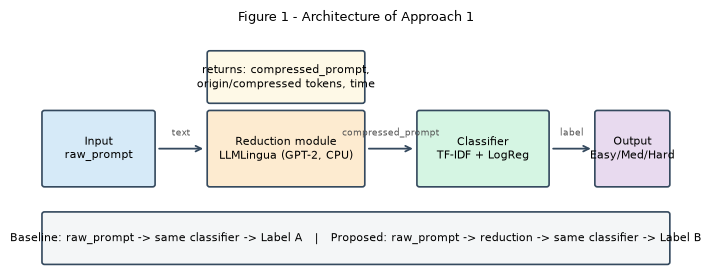

In [5]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(8.2, 3.1)); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 40)
def box(x, y, w, h, t, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4", fc=fc, ec="#34495e", lw=1.2))
    ax.text(x + w/2, y + h/2, t, ha="center", va="center", fontsize=8)
def arrow(x1, y1, x2, y2, t=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#34495e", lw=1.3))
    if t: ax.text((x1 + x2)/2, y1 + 2.2, t, ha="center", fontsize=6.5, color="#555")
box(1, 14, 17, 12, "Input\nraw_prompt", "#d6eaf8"); box(27, 14, 24, 12, "Reduction module\nLLMLingua (GPT-2, CPU)", "#fdebd0")
box(60, 14, 20, 12, "Classifier\nTF-IDF + LogReg", "#d5f5e3"); box(88, 14, 11, 12, "Output\nEasy/Med/Hard", "#e8daef")
arrow(18.6, 20, 26.4, 20, "text"); arrow(51.6, 20, 59.4, 20, "compressed_prompt"); arrow(80.6, 20, 87.4, 20, "label")
box(27, 28, 24, 8, "returns: compressed_prompt,\norigin/compressed tokens, time", "#fef9e7")
box(1, 1, 98, 8, "Baseline: raw_prompt -> same classifier -> Label A   |   Proposed: raw_prompt -> reduction -> same classifier -> Label B", "#f4f6f7")
plt.title("Figure 1 - Architecture of Approach 1", fontsize=9); plt.show()

## 5. One-prompt demo (the table on slide 12)
Train the classifier on the whole dataset, then take **one long prompt**, compress it, and compare predictions. As on your slide, one prompt only shows that the pipeline works – it does **not** measure accuracy (that is Sections 6–7).

In [6]:
[x for x in globals() if "Reducer" in x or "reducer" in x]

['BaseReducer', 'LLMLinguaReducer', 'HeuristicReducer', 'reducer']

In [7]:
!pip install "transformers==4.44.2"

  Using cached transformers-4.44.2-py3-none-any.whl.metadata (43 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached tokenizers-0.19.1.tar.gz (321 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Using cached transformers-4.44.2-py3-none-any.whl (9.5 MB)
Using cached huggingface_hub-0.36.2-py3-none-any.whl (566 kB)
Failed to build tokenizers


  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [62 lines of output]
      Rust not found, installing into a temporary directory
      Python reports SOABI: cp315-win_amd64
      Computed rustc target triple: x86_64-pc-windows-msvc
      Installation directory: C:\Users\HP\AppData\Local\puccinialin\puccinialin\Cache
      Rustup already downloaded
      Installing rust to C:\Users\HP\AppData\Local\puccinialin\puccinialin\Cache\rustup
      warn: it looks like you have an existing rustup settings file at:
      warn: C:\Users\HP\AppData\Local\puccinialin\puccinialin\Cache\rustup\settings.toml
      warn: installing msvc toolchain without its prerequisites
      info: profile set to minimal
      info: setting default host tuple to x86_64-pc-windows-msvc
      warn: Updating existing toolchain, profile choice will be ignored
      info: syncing channel updates for stable-x86_64-pc-windows-msvc
  

In [8]:
from transformers import DynamicCache
def _to_pairs(pk):
    if hasattr(pk, "layers"):     return tuple((l.keys, l.values) for l in pk.layers)
    if hasattr(pk, "key_cache"):  return tuple(zip(pk.key_cache, pk.value_cache))
    return tuple((x[0], x[1]) for x in pk)
def _to_cache(pairs):
    c = DynamicCache()
    for i, (k, v) in enumerate(pairs): c.update(k, v, i)
    return c
_orig_forward = reducer.comp.model.forward
def _patched_forward(*args, **kwargs):
    pkv = kwargs.get("past_key_values")
    if pkv is not None and not isinstance(pkv, DynamicCache):
        kwargs["past_key_values"] = _to_cache(_to_pairs(pkv))
    out = _orig_forward(*args, **kwargs)
    if getattr(out, "past_key_values", None) is not None:
        out.past_key_values = _to_pairs(out.past_key_values)
    return out
reducer.comp.model.forward = _patched_forward
print("patch applied")

patch applied


In [9]:
demo_clf = make_classifier().fit(df.prompt, df.label)
row = df[df.length_bucket == "long"].iloc[0]
r = reducer.reduce(row.prompt, 0.5)
y0, _ = predict_one_timed(demo_clf, row.prompt); y1, _ = predict_one_timed(demo_clf, r.compressed_prompt)
print(pd.DataFrame({"Measure": ["Original tokens", "Compressed tokens", "Token reduction", "Compression time",
                                "True label", "Original prediction", "Compressed prediction"],
                    "Value": [r.origin_tokens, r.compressed_tokens, f"{r.token_reduction_pct:.2f}%", f"{r.compression_time:.3f} s",
                              row.label, y0, y1]}).to_string(index=False))
print("\nCompressed prompt (first 400 chars):\n" + r.compressed_prompt[:400])

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1482 > 1024). Running this sequence through the model will result in indexing errors
c:\Users\HP\Downloads\task2_code\.venv\Lib\site-packages\transformers\utils\generic.py:1036: FutureWarning: `past_key_values` is deprecated and will be removed in version 5.40.0 for `GPT2LMHeadModel.forward`. Use `cache` instead.
  output = func(self, *args, **kwargs)


              Measure   Value
      Original tokens    1482
    Compressed tokens     652
      Token reduction  56.01%
     Compression time 7.327 s
           True label  Medium
  Original prediction  Medium
Compressed prediction  Medium

Compressed prompt (first 400 chars):
# export.py
def write_csv(file_path,):
    return result
          
  for in:
   return result
  =.get('mode', 'fast')
   =

def_,):
 
   in
  .debug('done
  .debug('done
     result(
 
     
All public functions are documented with their arguments and return values. Errors are reported with exceptions that from the base error class the package.ging uses the standard logging module.
All that class


## 6. Compress every prompt at every rate (subtask 2.9)
Conditions (all use the same prompts):
* `baseline` – original prompt, no compression
* `full@r` – compress the **whole** prompt (question included), keep a fraction *r* of tokens
* `protected@r` – compress **only the context**, keep the ask verbatim (oracle upper bound)

With LLMLingua this is the slow cell (CPU). Results are cached in `cache_llmlingua.json`, so you can stop and re-run it.

In [ ]:
cache_path = f"cache_{REDUCER}.json"
cache = json.load(open(cache_path)) if (REDUCER == "llmlingua" and os.path.exists(cache_path)) else {}
conds = [("baseline", None)] + [(m, r) for r in RATES for m in ("full", "protected")]
comp = {}
t_start = time.time(); done = 0
for mode, rate in conds:
    if mode == "baseline":
        comp[(mode, rate)] = [dict(text=p, o=reducer.count_tokens(p), c=reducer.count_tokens(p), t=0.0) for p in df.prompt]
        continue
    out_rows = []
    for n, (_, row) in enumerate(df.iterrows(), 1):
        key = f"{mode}|{rate}|{row.id}"
        if key not in cache:
            res = (reducer.reduce(row.prompt, rate) if mode == "full"
                   else reducer.reduce_protected(row.context, row.ask, row.ask_position == "start", rate))
            cache[key] = dict(text=res.compressed_prompt, o=res.origin_tokens, c=res.compressed_tokens, t=res.compression_time)
            done += 1
            if REDUCER == "llmlingua" and done % 10 == 0:
                json.dump(cache, open(cache_path, "w"))
                print(f"  {mode}@{rate}: {n}/{len(df)} prompts | {(time.time()-t_start)/60:.1f} min elapsed", flush=True)
        out_rows.append(cache[key])
    comp[(mode, rate)] = out_rows
    print(f"{mode}@{rate}: mean token reduction = {np.mean([100*(1-x['c']/x['o']) for x in out_rows]):.1f}%")
if REDUCER == "llmlingua": json.dump(cache, open(cache_path, "w"))

c:\Users\HP\Downloads\task2_code\.venv\Lib\site-packages\transformers\utils\generic.py:1036: FutureWarning: `past_key_values` is deprecated and will be removed in version 5.40.0 for `GPT2LMHeadModel.forward`. Use `cache` instead.
  output = func(self, *args, **kwargs)


  full@0.7: 10/144 prompts | 1.8 min elapsed
  full@0.7: 20/144 prompts | 4.3 min elapsed
  full@0.7: 30/144 prompts | 6.1 min elapsed
  full@0.7: 40/144 prompts | 6.3 min elapsed
  full@0.7: 50/144 prompts | 7.0 min elapsed
  full@0.7: 60/144 prompts | 8.3 min elapsed
  full@0.7: 70/144 prompts | 8.8 min elapsed
  full@0.7: 80/144 prompts | 9.2 min elapsed
  full@0.7: 90/144 prompts | 9.4 min elapsed
  full@0.7: 100/144 prompts | 9.9 min elapsed
  full@0.7: 110/144 prompts | 10.3 min elapsed
  full@0.7: 120/144 prompts | 10.9 min elapsed
  full@0.7: 130/144 prompts | 11.7 min elapsed
  full@0.7: 140/144 prompts | 12.3 min elapsed
full@0.7: mean token reduction = 21.7%


c:\Users\HP\Downloads\task2_code\.venv\Lib\site-packages\transformers\utils\generic.py:1036: FutureWarning: `past_key_values` is deprecated and will be removed in version 5.40.0 for `GPT2LMHeadModel.forward`. Use `cache` instead.
  output = func(self, *args, **kwargs)


  protected@0.7: 6/144 prompts | 12.7 min elapsed
  protected@0.7: 16/144 prompts | 13.3 min elapsed


## 7. Train, test and measure → MAIN RESULTS TABLE (subtask 2.9)
For each of `N_SPLITS` random stratified 70/30 splits: train once on **original** training prompts, then test every condition on the **same held-out prompts**. Numbers are averaged over splits.

Column guide: **Accuracy** (± spread over splits) · **Acc short / long** · **Token red.** mean % tokens removed · **Compr ms / Classif ms / Total ms** time per prompt · **Ask kept** % of the question's key words still present (approximate) · **Helped / Harmed** prompts per test split that became right / wrong versus the baseline.

In [ ]:
ask_words = lambda s: [w for w in re.findall(r"[a-z0-9_]+", s.lower()) if w not in STOPWORDS and len(w) > 2]
ask_terms = [set(ask_words(a)) for a in df.ask]
def present(text): return set(re.findall(r"[a-z0-9_]+", text.lower()))
def retention(i, text): return len(ask_terms[i] & present(text)) / max(1, len(ask_terms[i]))

strat = df.label + "_" + df.length_bucket
M = {c: dict(acc=[], f1=[], clf_ms=[], short=[], long=[], helped=[], harmed=[]) for c in conds}
failure_pool = []
for seed in range(N_SPLITS):
    tr, te = train_test_split(df.index, test_size=0.3, stratify=strat, random_state=seed)
    clf = make_classifier().fit(df.prompt[tr], df.label[tr])         # trained on ORIGINAL prompts only
    base_pred = None
    for c in conds:
        preds, times = [], []
        for i in te:
            y, dt = predict_one_timed(clf, comp[c][i]["text"]); preds.append(y); times.append(dt * 1000)
        preds = np.array(preds); truth = df.label[te].values; m = M[c]
        m["acc"].append((preds == truth).mean()); m["f1"].append(f1_score(truth, preds, average="macro")); m["clf_ms"].append(np.mean(times))
        for b in ("short", "long"):
            sel = (df.length_bucket[te] == b).values; m[b].append((preds[sel] == truth[sel]).mean())
        if c[0] == "baseline": base_pred = preds
        else:
            m["helped"].append(int(((base_pred != truth) & (preds == truth)).sum()))
            m["harmed"].append(int(((base_pred == truth) & (preds != truth)).sum()))
            if seed == 0 and c[0] == "full":               # collect failure cases from split 0
                for k, i in enumerate(te):
                    if base_pred[k] == truth[k] and preds[k] != truth[k]:
                        txt = comp[c][i]["text"]
                        failure_pool.append(dict(rate=c[1], id=int(df.id[i]), label=truth[k], baseline=base_pred[k], compressed=preds[k],
                                                 ask=df.ask[i], dropped=sorted(ask_terms[i] - present(txt)),
                                                 snippet=txt[:260] if df.ask_position[i] == "start" else txt[-260:]))

results = []
for c in conds:
    mode, rate = c; m = M[c]; cc = comp[c]
    red = [100 * (1 - x["c"] / x["o"]) for x in cc]
    comp_ms = np.mean([x["t"] * 1000 for x in cc]); clf_ms = np.mean(m["clf_ms"])
    results.append(dict(name="baseline" if mode == "baseline" else f"{mode}@{rate}", mode=mode, rate=rate,
        accuracy=np.mean(m["acc"]), acc_std=np.std(m["acc"]), macro_f1=np.mean(m["f1"]), acc_short=np.mean(m["short"]), acc_long=np.mean(m["long"]),
        token_red=np.mean(red), comp_ms=comp_ms, clf_ms=clf_ms, total_ms=comp_ms + clf_ms,
        ask_kept=np.mean([retention(i, x["text"]) for i, x in enumerate(cc)]),
        helped=np.mean(m["helped"]) if m["helped"] else np.nan, harmed=np.mean(m["harmed"]) if m["harmed"] else np.nan))
res_df = pd.DataFrame(results)
show = pd.DataFrame({"Condition": res_df.name,
    "Accuracy %": (100 * res_df.accuracy).round(1), "± std": (100 * res_df.acc_std).round(1), "Macro-F1": res_df.macro_f1.round(3),
    "Acc short %": (100 * res_df.acc_short).round(1), "Acc long %": (100 * res_df.acc_long).round(1),
    "Token red. %": res_df.token_red.round(1), "Compr ms": res_df.comp_ms.round(2), "Classif ms": res_df.clf_ms.round(2),
    "Total ms": res_df.total_ms.round(2), "Ask kept %": (100 * res_df.ask_kept).round(0),
    "Helped": res_df.helped.round(1), "Harmed": res_df.harmed.round(1)})
print(show.to_string(index=False))
res_df.to_csv(f"results_table_{REDUCER}.csv", index=False)

    Condition  Accuracy %  ± std  Macro-F1  Acc short %  Acc long %  Token red. %  Compr ms  Classif ms  Total ms  Ask kept %  Helped  Harmed
     baseline        82.7    4.9     0.828         99.1        66.7           0.0      0.00        1.09      1.09       100.0     NaN     NaN
     full@0.7        80.5    5.3     0.804         96.4        64.9          30.0      0.65        1.17      1.82       100.0     0.2     1.2
protected@0.7        85.0    4.0     0.850         99.1        71.1          24.6      0.81        1.15      1.96       100.0     1.0     0.0
     full@0.5        80.0    4.6     0.799         96.4        64.1          50.0      1.06        0.85      1.91       100.0     0.6     1.8
protected@0.5        89.1    3.6     0.890         99.1        79.2          40.9      0.75        0.82      1.56       100.0     3.0     0.2
     full@0.3        78.6    6.4     0.785         95.4        62.3          70.0      0.69        0.86      1.54        88.0     1.2     3.0
protec

## 8. Figures (subtasks 2.9, 2.10)
* **Figure 2** – accuracy vs token reduction. Red = compress whole prompt, blue = compress context only, dashed = baseline.
* **Figure 3** – accuracy on short vs long prompts for each condition (does compression fix the long-prompt problem?).
* **Figure 4** – time per prompt (compression + classification).

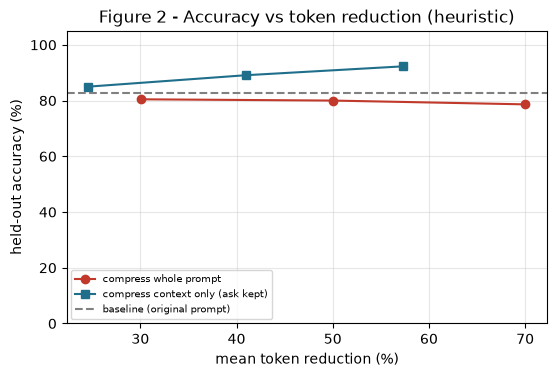

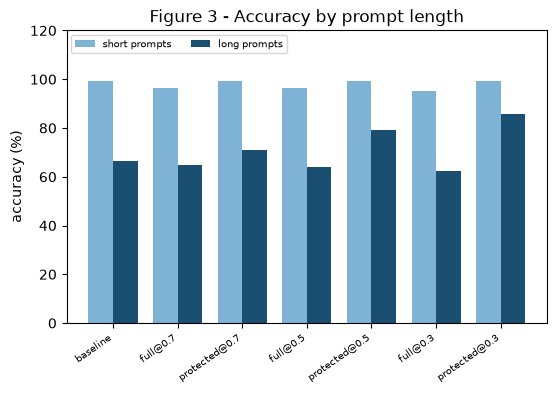

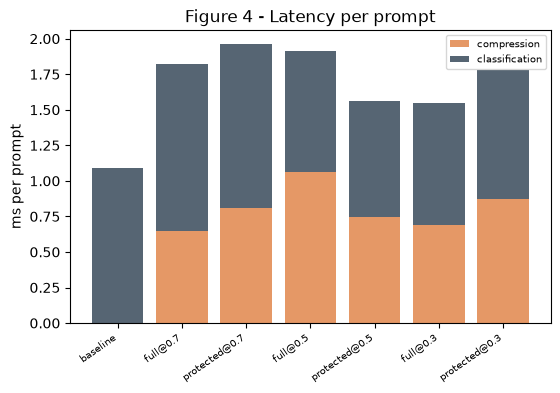

In [ ]:
base = res_df.iloc[0]; fullr = res_df[res_df["mode"] == "full"]; protr = res_df[res_df["mode"] == "protected"]
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(fullr.token_red, 100 * fullr.accuracy, "o-", color="#c0392b", label="compress whole prompt")
ax.plot(protr.token_red, 100 * protr.accuracy, "s-", color="#1f6f8b", label="compress context only (ask kept)")
ax.axhline(100 * base.accuracy, ls="--", color="grey", label="baseline (original prompt)")
ax.set_xlabel("mean token reduction (%)"); ax.set_ylabel("held-out accuracy (%)"); ax.set_ylim(0, 105)
ax.set_title(f"Figure 2 - Accuracy vs token reduction ({REDUCER})"); ax.legend(fontsize=7); ax.grid(alpha=.3); plt.show()

fig, ax = plt.subplots(figsize=(6.2, 3.8)); x = np.arange(len(res_df)); w = .38
ax.bar(x - w/2, 100 * res_df.acc_short, w, label="short prompts", color="#7fb3d5")
ax.bar(x + w/2, 100 * res_df.acc_long, w, label="long prompts", color="#1b4f72")
ax.set_xticks(x); ax.set_xticklabels(res_df.name, rotation=35, ha="right", fontsize=7)
ax.set_ylabel("accuracy (%)"); ax.set_ylim(0, 120); ax.legend(fontsize=7, ncol=2, loc="upper left"); ax.set_title("Figure 3 - Accuracy by prompt length"); plt.show()

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.bar(x, res_df.comp_ms, label="compression", color="#e59866")
ax.bar(x, res_df.clf_ms, bottom=res_df.comp_ms, label="classification", color="#566573")
ax.set_xticks(x); ax.set_xticklabels(res_df.name, rotation=35, ha="right", fontsize=7)
ax.set_ylabel("ms per prompt"); ax.legend(fontsize=7); ax.set_title("Figure 4 - Latency per prompt"); plt.show()

## 9. Findings (subtask 2.10)
The text below is generated from the numbers above, so it stays correct if you change `REDUCER` or `RATES`.

In [ ]:
P = lambda v: f"{100*v:.1f}%"
print(f"1. BASELINE: {P(base.accuracy)} accuracy overall - {P(base.acc_short)} on short prompts but only {P(base.acc_long)} on long ones.")
print("   -> long auxiliary context hurts the classifier; this is the problem Approach 1 tries to fix.\n")
print(f"2. COMPRESS WHOLE PROMPT ({fullr.token_red.min():.0f}-{fullr.token_red.max():.0f}% fewer tokens): accuracy {P(fullr.accuracy.min())}-{P(fullr.accuracy.max())}"
      + (" - no gain over the baseline." if fullr.accuracy.max() <= base.accuracy + 0.005 else " - compare with the +/- spread before calling it a gain."))
print(f"   {fullr.harmed.min():.1f}-{fullr.harmed.max():.1f} test prompts per split went from correct to WRONG.\n")
print(f"3. COMPRESS CONTEXT ONLY, ASK KEPT ({protr.token_red.min():.0f}-{protr.token_red.max():.0f}% fewer tokens): accuracy {P(protr.accuracy.min())}-{P(protr.accuracy.max())}"
      + (f" - ABOVE the baseline ({P(base.accuracy)})." if protr.accuracy.max() > base.accuracy + 0.005 else "."))
if protr.accuracy.max() > base.accuracy + 0.005:
    print("   Hypothesis (not tested): TF-IDF is diluted by noise words; removing context raises the weight of the ask. The gain comes from")
    print("   protecting the ask, NOT from the compressor understanding difficulty - and it needs the ask to be located (hard in real prompts).\n")
print(f"4. LATENCY: compression adds ~{fullr.comp_ms.mean():.2f} ms per prompt on top of ~{base.clf_ms:.2f} ms classification in this run.")
if REDUCER != "llmlingua":
    print("   (stand-in compressor - says nothing about LLMLingua. Your slide-12 LLMLingua/GPT-2/CPU run took 0.83 s for ONE prompt.)")
print("\nCAVEATS: synthetic data, ~44 test prompts per split -> differences of a few points are within the split-to-split spread.")

1. BASELINE: 82.7% accuracy overall - 99.1% on short prompts but only 66.7% on long ones.
   -> long auxiliary context hurts the classifier; this is the problem Approach 1 tries to fix.

2. COMPRESS WHOLE PROMPT (30-70% fewer tokens): accuracy 78.6%-80.5% - no gain over the baseline.
   1.2-3.0 test prompts per split went from correct to WRONG.

3. COMPRESS CONTEXT ONLY, ASK KEPT (25-57% fewer tokens): accuracy 85.0%-92.3% - ABOVE the baseline (82.7%).
   Hypothesis (not tested): TF-IDF is diluted by noise words; removing context raises the weight of the ask. The gain comes from
   protecting the ask, NOT from the compressor understanding difficulty - and it needs the ask to be located (hard in real prompts).

4. LATENCY: compression adds ~0.80 ms per prompt on top of ~1.09 ms classification in this run.
   (stand-in compressor - says nothing about LLMLingua. Your slide-12 LLMLingua/GPT-2/CPU run took 0.83 s for ONE prompt.)

CAVEATS: synthetic data, ~44 test prompts per split -> diffe

## 10. Failure cases (subtask 2.10)
**From your LLMLingua prototype (slide 13):**
*"Please analyse the possible **causes** and suggest a solution."* → *"Please analyse the possible and suggest a solution."* One word lost, yet the object of the request is gone → token reduction alone is not a safe success measure.

**From this run:** prompts the baseline classified correctly but whole-prompt compression got wrong (split 0).

In [ ]:
failure_pool.sort(key=lambda f: (-len(f["dropped"]), f["rate"]))
for f in failure_pool[:5]:
    print(f"[id {f['id']}] true={f['label']}  baseline={f['baseline']} -> compressed={f['compressed']}  (rate {f['rate']})")
    print("  ask:", f["ask"])
    print("  ask words dropped:", f["dropped"] or "none (label changed because surrounding tokens changed)")
    print("  compressed snippet:", repr(f["snippet"][:160]), "\n")
lost_mid = [i for i in range(len(df)) if ask_terms[i] - present(comp[("full", sorted(RATES)[len(RATES)//2])][i]["text"])]
print(f"At rate {sorted(RATES)[len(RATES)//2]}, {100*len(lost_mid)/len(df):.0f}% of prompts lost at least one key word of the ask in this run.")

[id 33] true=Easy  baseline=Easy -> compressed=Medium  (rate 0.3)
  ask: Fix the typo in the variable name `amount_cents` inside the payment service.
  ask words dropped: ['amount_cents', 'inside']
  compressed snippet: 'Fix typo variable name payment service\npayments py\ndef charge_card\nresult\ncontinue\nvalue config get mode fast' 

[id 112] true=Hard  baseline=Hard -> compressed=Medium  (rate 0.3)
  ask: Please reproduce and fix the deadlock between the scheduler and the I/O thread pool in the session store that happens only on NUMA machines. Explain your reasoning step by step.
  ask words dropped: ['pool']
  compressed snippet: 'ttempt\n24 34 098 Request 321a0828 completed 77 ms status 200\n56 015 Connection size 688 active 5 idle 304\n17 10 51 952 api router 666\nPlease reproduce fix deadl' 

[id 61] true=Hard  baseline=Hard -> compressed=Medium  (rate 0.3)
  ask: Optimize the CSV exporter from O(n^2) to O(n log n) for ten million records while keeping exact results and bounded

## 11. Summary for the Task 5 team comparison (subtask 2.11)

| Strengths | Weaknesses |
|---|---|
| Simple pipeline with clear interfaces | Does **not understand difficulty** |
| Easy to plug in: Python package | Can drop key words (e.g. "causes") – meaning can change |
| Same classifier on both paths → fair comparison | Adds compression time (slow on CPU) |

**Preliminary verdict:** the idea is reasonable and token savings are cheap, but it is **not proven**. Protecting the question while compressing the context looks promising; compressing the whole prompt risks information loss. A real conclusion needs the full **LLMLingua** run on the shared Task 1 evaluation set.
